# 01 — WaterBench-Iowa: load, audit and first look

**In plain words.** Before building any forecast model, we first prove the data can be trusted. This notebook loads all 125 river gauges, checks units, timestamps and missing values, and looks at how the rivers behave. Every number it prints is a finding you can put on a slide.

**How to run.** Keep this notebook in your `FYP` folder, next to `data_time_series/` and `catchment_relationship.csv`. Then use *Kernel → Restart & Run All*. It needs `pip install pandas numpy matplotlib networkx pyarrow jupyter`.

**What it produces:** figures in `figures/`, a cleaned table in `processed/waterbench_ts_clean.parquet`, and `processed/static_attributes.csv`.

| Section | Question it answers |
|---|---|
| 1–2 | What is in the files, and are they all loaded correctly? |
| 3 | Does the data match the paper's documentation (units, sizes, hourly steps)? |
| 4 | How are the gauges connected along the rivers? |
| 5 | How much flow data is missing, where and when? |
| 6 | Are there impossible or suspicious values? |
| 7 | Does flow respond *after* rain (is the clock consistent)? |
| 8 | What did we learn, and what do we decide next? |

> **Rule for this whole project:** the final water year (2018) is the test set. In this notebook we only *count* things in it (e.g. missing data). Any threshold, lag or scaler is computed on training years only.

In [1]:
# One-time install (run in a terminal if anything is missing):
#   pip install pandas numpy matplotlib networkx pyarrow jupyter

import re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8C8C8C"

SEED = 42
np.random.seed(SEED)

# ---- paths: this notebook sits in your FYP folder ----
ROOT = Path(".")
TS_DIR = ROOT / "data_time_series"
REL_FILE = ROOT / "catchment_relationship.csv"
FIG_DIR = ROOT / "figures";   FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = ROOT / "processed"; OUT_DIR.mkdir(exist_ok=True)

# ---- constants ----
SENTINEL = -9999                 # how the paper says missing flow is coded
CFS_TO_CMS = 0.0283168           # cubic feet/second -> cubic metres/second
EXPECTED_ROWS = 61_368           # 1 Oct 2011 00:00 -> 30 Sep 2018 23:00, hourly
TRAIN_LAST_WY, VAL_WY, TEST_WY = 2016, 2017, 2018
FLAT_HOURS = 24                  # identical flow for this many hours -> flag for review
JUMP_MULT = 10                   # one-hour spike if jump > this x the 99th percentile of hourly changes

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.3


## 1. Find the files and peek at one

**In plain words.** Look at one gauge file before loading everything, so we know the column names and what a row looks like. From your screenshot the columns should be `datetime, precipitation, et, discharge, travel_time, area, slope` and four soil columns.

In [2]:
files = sorted(TS_DIR.rglob("*.csv"))
if not files:
    raise FileNotFoundError(f"No CSV files under {TS_DIR.resolve()} - check the folder name and where this notebook is saved.")

print(f"{len(files)} CSV files under {TS_DIR.resolve()}")
print("first file names:", [f.name for f in files[:5]])

sample = pd.read_csv(files[0])
print("\nColumns:", list(sample.columns))
print("Shape of one file:", sample.shape)
display(sample.head(3))
display(sample.dtypes.to_frame("dtype").T)

125 CSV files under /Users/champakjyotikonwar/My_Projects/FYP/data_time_series
first file names: ['1609_data.csv', '1688_data.csv', '519_data.csv', '521_data.csv', '522_data.csv']

Columns: ['datetime', 'precipitation', 'et', 'discharge', 'travel_time', 'area', 'slope', 'loam', 'silt', 'sandy_clay_loam', 'silty_clay_loam']
Shape of one file: (61368, 11)


,datetime,precipitation,et,discharge,travel_time,area,slope,loam,silt,sandy_clay_loam,silty_clay_loam
0,2011-10-01 00:00:00,0.0,20,170.0,112.0,4863.0,0.001805,0.385304,0.219558,0.283461,0.111677
1,2011-10-01 01:00:00,0.0,20,170.0,112.0,4863.0,0.001805,0.385304,0.219558,0.283461,0.111677
2,2011-10-01 02:00:00,0.0,20,170.0,112.0,4863.0,0.001805,0.385304,0.219558,0.283461,0.111677


,datetime,precipitation,et,discharge,travel_time,area,slope,loam,silt,sandy_clay_loam,silty_clay_loam
dtype,str,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64


## 2. Load all gauges into one table

**In plain words.** We stack all 125 files into one long table with a `station` column. The catchment properties (area, slope, soil...) never change, so they go into a separate small table with one row per station instead of being repeated 61,368 times.

While loading we also:
- count how many `-9999` (the "missing" code) and blank values exist **before** cleaning, so nothing is hidden;
- turn `-9999` into `NaN` (an empty value);
- convert flow from cubic feet per second to m³/s (`q_cms`);
- label each row with its **water year** (1 Oct–30 Sep) and its split: train 2012–2016, validation 2017, test 2018.

In [3]:
TS_COLS = ["precipitation", "et", "discharge"]

def station_id_from(path):
    m = re.search(r"\d+", path.stem)
    if m is None:
        raise ValueError(f"No station number in file name {path.name}")
    return str(int(m.group()))

ts_parts, static_rows, audit_rows, offsets = [], [], [], {}
sentinel_counts = {c: 0 for c in TS_COLS}
nan_counts = {c: 0 for c in TS_COLS}
total = 0

for f in files:
    sid = station_id_from(f)
    d = pd.read_csv(f, parse_dates=["datetime"])
    static_cols = [c for c in d.columns if c not in ["datetime"] + TS_COLS]

    # count the raw sentinel / blank values BEFORE any cleaning
    for c in TS_COLS:
        sentinel_counts[c] += int((d[c] == SENTINEL).sum())
        nan_counts[c] += int(d[c].isna().sum())

    # fixed catchment properties: keep one row, and check they really are constant
    const = bool((d[static_cols].nunique(dropna=False) <= 1).all())
    static_rows.append({"station": sid, **d[static_cols].iloc[0].to_dict()})

    dt = d["datetime"]
    audit_rows.append({
        "station": sid, "file": f.name, "n_rows": len(d),
        "first": dt.iloc[0], "last": dt.iloc[-1],
        "sorted": bool(dt.is_monotonic_increasing),
        "n_dupe_times": int(dt.duplicated().sum()),
        "all_hourly": bool((dt.diff().dropna() == pd.Timedelta(hours=1)).all()),
        "static_constant": const,
    })

    ts = d[["datetime"] + TS_COLS].copy()
    ts[TS_COLS] = ts[TS_COLS].replace(SENTINEL, np.nan)
    ts["station"] = sid
    ts_parts.append(ts)
    offsets[sid] = (total, total + len(ts))
    total += len(ts)

df = pd.concat(ts_parts, ignore_index=True)
del ts_parts

static = pd.DataFrame(static_rows).set_index("station")
audit = pd.DataFrame(audit_rows).set_index("station")

# compact types + derived columns
df["station"] = df["station"].astype("category")
for c in ["precipitation", "et"]:
    df[c] = df[c].astype("float32")
df["q_cms"] = df["discharge"] * CFS_TO_CMS
df["wy"] = (df["datetime"].dt.year + (df["datetime"].dt.month >= 10)).astype("int16")
df["month"] = df["datetime"].dt.month.astype("int8")
split = np.select([df["wy"] <= TRAIN_LAST_WY, df["wy"] == VAL_WY, df["wy"] == TEST_WY],
                  ["train", "val", "test"], default="other")
df["split"] = pd.Categorical(split, categories=["train", "val", "test", "other"])

print(f"Loaded {len(df):,} rows x {df.shape[1]} columns from {len(offsets)} stations")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print("Raw -9999 counts :", sentinel_counts)
print("Raw blank counts :", nan_counts)
print("Static columns   :", list(static.columns))
display(df.head(3))

Loaded 7,671,000 rows x 9 columns from 125 stations
Memory: 284 MB
Raw -9999 counts : {'precipitation': 0, 'et': 0, 'discharge': 1162562}
Raw blank counts : {'precipitation': 1864, 'et': 0, 'discharge': 0}
Static columns   : ['travel_time', 'area', 'slope', 'loam', 'silt', 'sandy_clay_loam', 'silty_clay_loam']


,datetime,precipitation,et,discharge,station,q_cms,wy,month,split
0,2011-10-01 00:00:00,0.0,20.0,170.0,1609,4.813856,2012,10,train
1,2011-10-01 01:00:00,0.0,20.0,170.0,1609,4.813856,2012,10,train
2,2011-10-01 02:00:00,0.0,20.0,170.0,1609,4.813856,2012,10,train


In [4]:
# ---- small helpers used in later sections ----
def S(sid):
    """Rows of one station (a cheap slice of the big table)."""
    a, b = offsets[sid]
    return df.iloc[a:b]

def run_bounds(mask):
    """Start and (exclusive) end index of every run of True in a boolean array."""
    m = np.asarray(mask, dtype=np.int8)
    d = np.diff(np.concatenate(([0], m, [0])))
    return np.where(d == 1)[0], np.where(d == -1)[0]

def run_lengths(mask):
    s, e = run_bounds(mask)
    return e - s

## 3. Does the data match the documentation?

**In plain words.** A checklist of things the paper says should be true. Every line says `PASS` or `CHECK`. A `CHECK` is not automatically a problem; it means *look at this before trusting the data*.

In [5]:
results = []
def check(name, ok, detail=""):
    results.append({"check": name, "result": "PASS" if ok else "CHECK", "detail": detail})

sids = list(offsets)
soil_cols = [c for c in static.columns if c not in ("travel_time", "area", "slope")]

et_ref = S(sids[0])["et"].to_numpy()
et_same = all(len(S(s)) == len(et_ref) and np.allclose(S(s)["et"].to_numpy(), et_ref, equal_nan=True) for s in sids)
soil_sum = static[soil_cols].sum(axis=1)
n_neg_q = int((df["discharge"] < 0).sum())
n_neg_p = int((df["precipitation"] < 0).sum())

check("125 station files", len(files) == 125, f"{len(files)} files")
check("station ids unique", audit.index.is_unique)
check(f"{EXPECTED_ROWS:,} rows in every file", (audit["n_rows"] == EXPECTED_ROWS).all(),
      f"min {audit['n_rows'].min():,} / max {audit['n_rows'].max():,}")
check("same first and last timestamp in every file", audit["first"].nunique() == 1 and audit["last"].nunique() == 1,
      f"{audit['first'].min()} -> {audit['last'].max()}")
check("timestamps sorted", audit["sorted"].all())
check("no duplicate timestamps", (audit["n_dupe_times"] == 0).all())
check("every step is exactly 1 hour", audit["all_hourly"].all())
check("static columns constant inside each file", audit["static_constant"].all())
check("ET is the same series in every station (statewide monthly value)", et_same)
check("soil shares add up to about 1 (so they are fractions, not %)", soil_sum.between(0.98, 1.02).all(),
      f"sum ranges {soil_sum.min():.3f} to {soil_sum.max():.3f}")
check("no negative flow", n_neg_q == 0, f"{n_neg_q:,} negative flow rows")
check("no negative rain", n_neg_p == 0, f"{n_neg_p:,} negative rain rows")
check("missing flow is coded as -9999 (as documented)", sentinel_counts["discharge"] > 0,
      f"{sentinel_counts['discharge']:,} rows with -9999, {nan_counts['discharge']:,} blank rows")

display(pd.DataFrame(results))

,check,result,detail
0,125 station files,PASS,125 files
1,station ids unique,PASS,
2,"61,368 rows in every file",PASS,"min 61,368 / max 61,368"
3,same first and last timestamp in every file,PASS,2011-10-01 00:00:00 -> 2018-09-30 23:00:00
4,timestamps sorted,PASS,
5,no duplicate timestamps,PASS,
6,every step is exactly 1 hour,PASS,
7,static columns constant inside each file,PASS,
8,ET is the same series in every station (statewide monthly value),PASS,
9,"soil shares add up to about 1 (so they are fractions, not %)",PASS,sum ranges 0.991 to 1.000


### Data dictionary

**In plain words.** One table that says what each column is and in which unit. If you cannot state a column's unit, you cannot trust any plot or model that uses it. Units below come from the WaterBench paper; the last column shows what we actually observe, so you can sanity-check them.

In [6]:
def mmm(s):
    s = pd.Series(s).dropna()
    return f"{s.min():,.4g} / {s.median():,.4g} / {s.max():,.4g}"

dictionary = pd.DataFrame([
    ("datetime",        "Hourly timestamp",                                           "date-time (time zone NOT documented, see section 7)", f"{df['datetime'].min()} to {df['datetime'].max()}"),
    ("precipitation",   "Catchment-average rain (NOAA Stage IV radar)",               "mm per hour",              mmm(df["precipitation"])),
    ("et",              "Evapotranspiration, one monthly value for all of Iowa",      "mm per month",             mmm(df["et"])),
    ("discharge",       "River flow at the gauge (USGS)",                             "cubic feet per second",    mmm(df["discharge"])),
    ("q_cms (derived)", "Same flow converted by us",                                  "cubic metres per second",  mmm(df["q_cms"])),
    ("travel_time",     "Concentration time: how long water takes to reach the gauge","hours",                    mmm(static["travel_time"])),
    ("area",            "Catchment area",                                             "km2",                      mmm(static["area"])),
    ("slope",           "Mean slope",                                                 "unit to be confirmed below", mmm(static["slope"])),
    (", ".join(soil_cols), "Share of each soil type",                                "fraction (sums to 1)",     "see static table"),
], columns=["column", "meaning", "unit", "observed min / median / max"])
display(dictionary)

,column,meaning,unit,observed min / median / max
0,datetime,Hourly timestamp,"date-time (time zone NOT documented, see section 7)",2011-10-01 00:00:00 to 2018-09-30 23:00:00
1,precipitation,Catchment-average rain (NOAA Stage IV radar),mm per hour,0 / 0 / 60
2,et,"Evapotranspiration, one monthly value for all of Iowa",mm per month,13 / 32 / 121
3,discharge,River flow at the gauge (USGS),cubic feet per second,0 / 348 / 1.07e+05
4,q_cms (derived),Same flow converted by us,cubic metres per second,"0 / 9.854 / 3,030"
5,travel_time,Concentration time: how long water takes to reach the gauge,hours,2 / 53 / 315
6,area,Catchment area,km2,"6 / 1,918 / 3.645e+04"
7,slope,Mean slope,unit to be confirmed below,0.000375 / 0.001805 / 0.00432
8,"loam, silt, sandy_clay_loam, silty_clay_loam",Share of each soil type,fraction (sums to 1),see static table


### The 125 catchments: sizes, response times and soils

**In plain words.** The catchments are extremely different. A 6 km² creek reacts within hours; a 36,000 km² river takes days. One model has to cope with both, which is why we give it the catchment properties as inputs. The table below compares what we see with the paper's published statistics, which is a quick way to catch unit mistakes.

,"observed (min, median, max)","paper, ESSD Table 3"
area (km2),"(6.0, 1918.0, 36453.0)","(6, 1918, 36453)"
travel_time (h),"(2.0, 53.0, 315.0)","(2, 53, 315)"
slope,"(0.0004, 0.0018, 0.0043)","(0.38, 1.8, 4.32)"


Slope: median ratio to the paper is 0.0010 -> units unclear. Do not use slope as an interpretable number until resolved.


Spearman correlation between area and travel_time: 0.97  (large catchments respond slower)


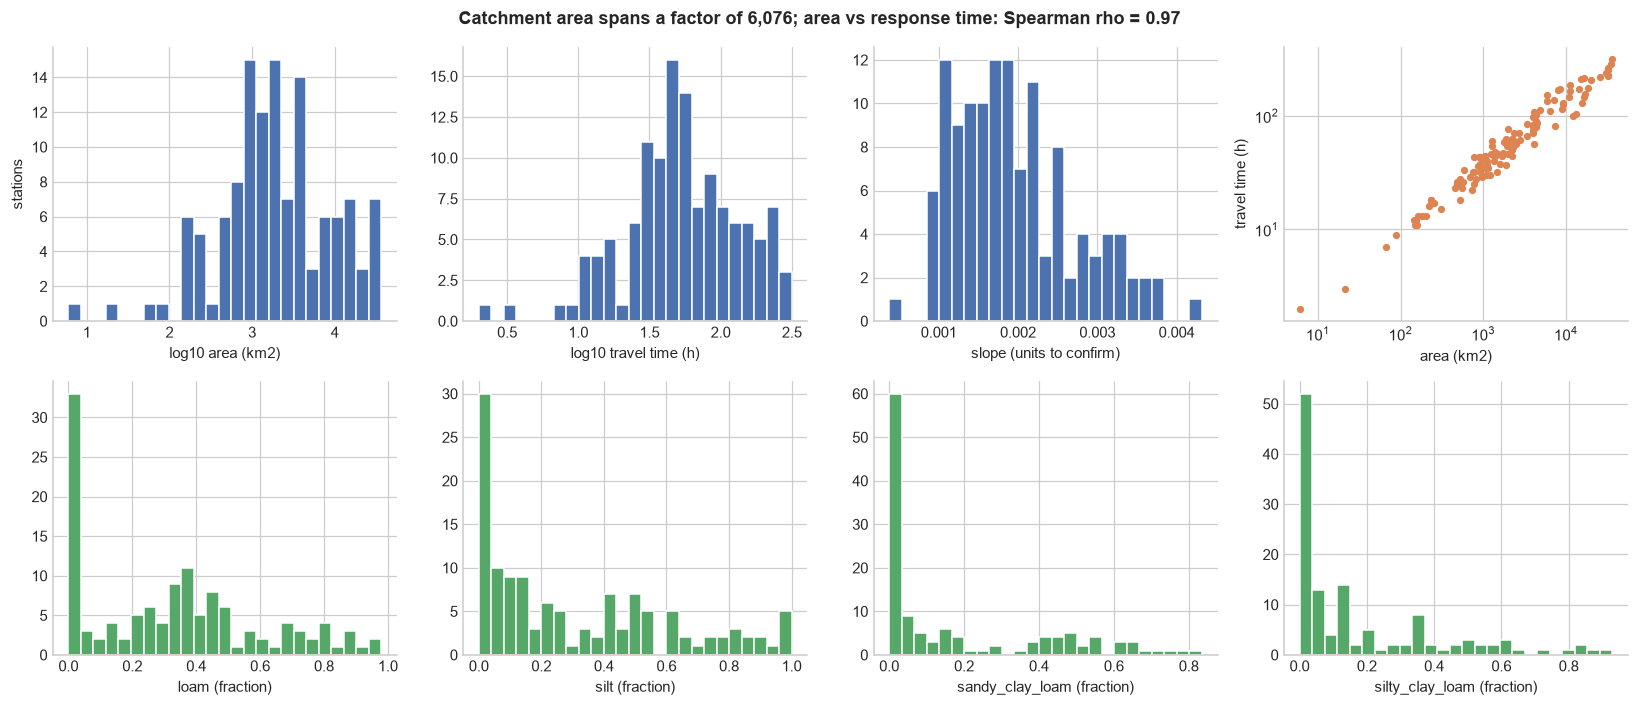

In [7]:
def trip(s): return tuple(round(float(v), 4) for v in (s.min(), s.median(), s.max()))

compare = pd.DataFrame({
    "observed (min, median, max)": [trip(static["area"]), trip(static["travel_time"]), trip(static["slope"])],
    "paper, ESSD Table 3":         [(6, 1918, 36453), (2, 53, 315), (0.38, 1.80, 4.32)],
}, index=["area (km2)", "travel_time (h)", "slope"])
display(compare)

r = static["slope"].median() / 1.80
if 0.005 < r < 0.02:
    print("Slope: median is about 1/100 of the paper's, so the files probably store slope as a FRACTION (m/m), not percent.")
elif 0.5 < r < 2:
    print("Slope: matches the paper's percent values.")
else:
    print(f"Slope: median ratio to the paper is {r:.4f} -> units unclear. Do not use slope as an interpretable number until resolved.")

rho = static["area"].corr(static["travel_time"], method="spearman")
print(f"Spearman correlation between area and travel_time: {rho:.2f}  (large catchments respond slower)")

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
axes[0, 0].hist(np.log10(static["area"]), bins=25, color=BLUE, edgecolor="white")
axes[0, 0].set_xlabel("log10 area (km2)"); axes[0, 0].set_ylabel("stations")
axes[0, 1].hist(np.log10(static["travel_time"]), bins=25, color=BLUE, edgecolor="white")
axes[0, 1].set_xlabel("log10 travel time (h)")
axes[0, 2].hist(static["slope"], bins=25, color=BLUE, edgecolor="white")
axes[0, 2].set_xlabel("slope (units to confirm)")
axes[0, 3].scatter(static["area"], static["travel_time"], s=14, color=ORANGE)
axes[0, 3].set_xscale("log"); axes[0, 3].set_yscale("log")
axes[0, 3].set_xlabel("area (km2)"); axes[0, 3].set_ylabel("travel time (h)")
for ax, c in zip(axes[1], soil_cols[:4]):
    ax.hist(static[c], bins=25, color=GREEN, edgecolor="white"); ax.set_xlabel(f"{c} (fraction)")
for ax in axes[1][len(soil_cols[:4]):]:
    ax.set_visible(False)
fig.suptitle(f"Catchment area spans a factor of {static['area'].max() / static['area'].min():,.0f}; "
             f"area vs response time: Spearman rho = {rho:.2f}", fontweight="bold")
savefig("01_static_attributes.png")

## 4. How the gauges are connected

**In plain words.** `catchment_relationship.csv` says which gauge sits upstream of which. That matters for the gate: an upstream gauge sees a flood hours before the downstream one does, which is free warning time. From your screenshot, `station_id` is the **downstream** gauge and `upstream_id` is the gauge feeding it (some stations, such as 628, have two upstream gauges).

Relationship file: 98 rows, 63 stations have at least one upstream gauge
Headwater stations (nothing upstream): 62
   paper says: 63 with upstream gauges, 62 headwater, largest tree = 27 upstream gauges
Downstream catchment is larger than its upstream one in 100% of 98 links (should be ~100%, otherwise the direction is reversed)
Largest connected river tree: 34 gauges


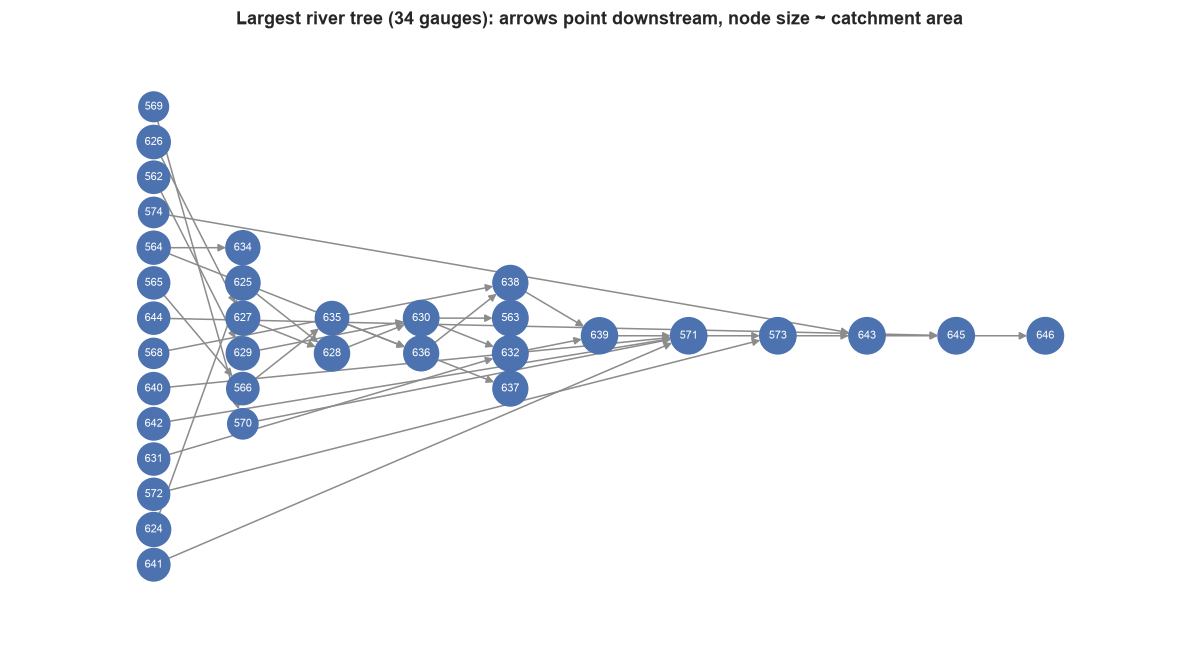

In [8]:
rel = pd.read_csv(REL_FILE)
rel["station_id"] = rel["station_id"].astype(int).astype(str)
rel["upstream_id"] = rel["upstream_id"].astype(int).astype(str)

G = nx.DiGraph()
G.add_nodes_from(static.index)
G.add_edges_from(zip(rel["upstream_id"], rel["station_id"]))        # arrow points downstream

ids_in_rel = set(rel["station_id"]) | set(rel["upstream_id"])
not_in_files = sorted(ids_in_rel - set(static.index))
print(f"Relationship file: {len(rel)} rows, {rel['station_id'].nunique()} stations have at least one upstream gauge")
print(f"Headwater stations (nothing upstream): {sum(G.in_degree(n) == 0 for n in static.index)}")
print("   paper says: 63 with upstream gauges, 62 headwater, largest tree = 27 upstream gauges")
if not_in_files:
    print(f"IDs in the relationship file but with no data file: {not_in_files}")

pairs = [(static.loc[u, "area"], static.loc[v, "area"]) for u, v in G.edges if u in static.index and v in static.index]
frac = np.mean([down > up for up, down in pairs]) if pairs else np.nan
print(f"Downstream catchment is larger than its upstream one in {frac:.0%} of {len(pairs)} links (should be ~100%, otherwise the direction is reversed)")

comp = max(nx.weakly_connected_components(G), key=len)
Gc = G.subgraph(comp).copy()
print(f"Largest connected river tree: {Gc.number_of_nodes()} gauges")

try:
    layer = {}
    for k, nodes in enumerate(nx.topological_generations(Gc)):
        for n in nodes:
            layer[n] = k
    nx.set_node_attributes(Gc, layer, "layer")
    pos = nx.multipartite_layout(Gc, subset_key="layer", align="vertical")
except Exception:
    pos = nx.spring_layout(Gc, seed=SEED)

sizes = [200 + 80 * np.log10(static.loc[n, "area"]) if n in static.index else 200 for n in Gc.nodes]
colors = [BLUE if n in static.index else GREY for n in Gc.nodes]
fig, ax = plt.subplots(figsize=(11, 6))
nx.draw_networkx(Gc, pos, node_size=sizes, node_color=colors, font_size=7, font_color="white",
                 arrows=True, arrowsize=10, edge_color=GREY, ax=ax)
ax.margins(0.1); ax.axis("off")
note = "; grey = listed in the relationship file but no data file" if not_in_files else ""
ax.set_title(f"Largest river tree ({Gc.number_of_nodes()} gauges): arrows point downstream, node size ~ catchment area{note}")
savefig("02_river_network.png")

## 5. Missing data

**In plain words.** Flow gauges break, freeze in winter, or lose their record. We need to know how much is missing, where, and how long the gaps are, because that decides how we handle it. The plan from our strategy document: **mask missing flow in the loss function, never invent values for it.** Short gaps in *input* columns can be filled later; long gaps cannot.

Completeness rating used below: Complete > 99%, Mostly complete 95–99%, Incomplete 80–95%, Sparse < 80%.

,% present,rating
discharge,84.844714,Incomplete
precipitation,99.975701,Complete
et,100.000000,Complete


,"flow missing, % (observed)","flow missing, % (paper)"
min,0.690914,0.69
median,16.141963,16.14
mean,15.155286,15.16
max,33.141051,33.14


Rain missing per station: median 0.016%, max 0.037%  (paper: negligible)
Flow missing by split (%): {'train': 18.91, 'val': 10.33, 'test': 1.19}


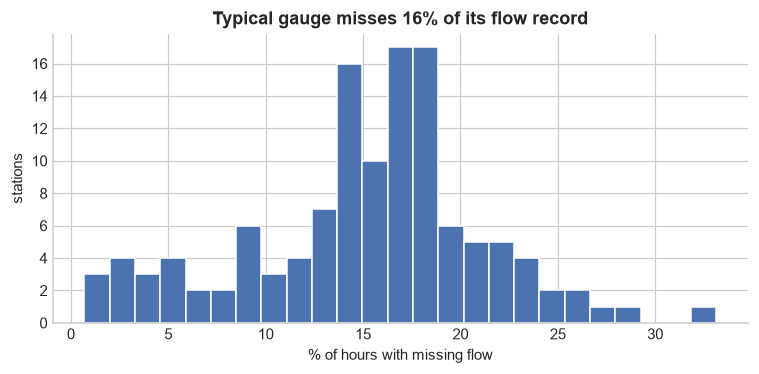

In [9]:
q_missing = df["q_cms"].isna().to_numpy()

def rating(pct_present):
    return ("Complete" if pct_present > 99 else "Mostly complete" if pct_present > 95
            else "Incomplete" if pct_present > 80 else "Sparse")

col_complete = pd.DataFrame({
    "% present": [100 * (1 - df[c].isna().mean()) for c in ["discharge", "precipitation", "et"]]
}, index=["discharge", "precipitation", "et"])
col_complete["rating"] = col_complete["% present"].map(rating)
display(col_complete)

miss_rate = df.groupby("station", observed=True)["q_cms"].apply(lambda s: s.isna().mean()) * 100
precip_miss = df.groupby("station", observed=True)["precipitation"].apply(lambda s: s.isna().mean()) * 100

summary = pd.DataFrame({
    "flow missing, % (observed)": [miss_rate.min(), miss_rate.median(), miss_rate.mean(), miss_rate.max()],
    "flow missing, % (paper)":    [0.69, 16.14, 15.16, 33.14],
}, index=["min", "median", "mean", "max"])
display(summary)
print(f"Rain missing per station: median {precip_miss.median():.3f}%, max {precip_miss.max():.3f}%  (paper: negligible)")

by_split = df.groupby("split", observed=True)["q_cms"].apply(lambda s: 100 * s.isna().mean())
print("Flow missing by split (%):", by_split.round(2).to_dict())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(miss_rate, bins=25, color=BLUE, edgecolor="white")
ax.set_xlabel("% of hours with missing flow"); ax.set_ylabel("stations")
ax.set_title(f"Typical gauge misses {miss_rate.median():.0f}% of its flow record")
savefig("03_missing_rate_hist.png")

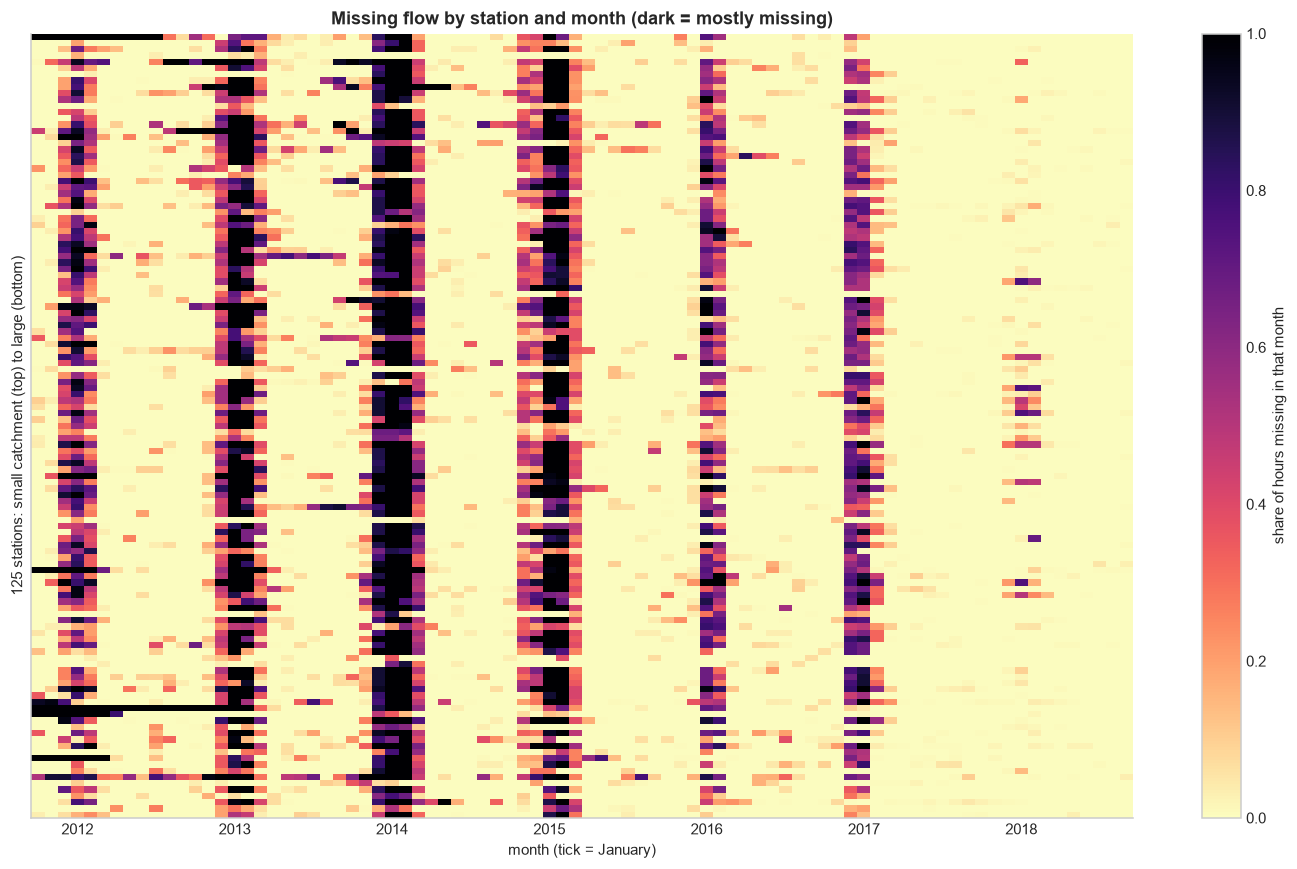

In [10]:
# station x month heatmap of missing flow, stations sorted from small to large catchment
ym = (df["datetime"].dt.year * 100 + df["datetime"].dt.month).astype("int32")
tmp = pd.DataFrame({"station": df["station"], "ym": ym, "miss": q_missing})
heat = tmp.groupby(["station", "ym"], observed=True)["miss"].mean().unstack()
heat = heat.loc[static["area"].sort_values().index]

cols = list(heat.columns)
ticks = [i for i, c in enumerate(cols) if c % 100 == 1]
fig, ax = plt.subplots(figsize=(13, 8))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="magma_r", vmin=0, vmax=1, interpolation="nearest")
ax.grid(False)
ax.set_xticks(ticks); ax.set_xticklabels([str(cols[i] // 100) for i in ticks])
ax.set_yticks([])
ax.set_xlabel("month (tick = January)"); ax.set_ylabel(f"{heat.shape[0]} stations: small catchment (top) to large (bottom)")
ax.set_title("Missing flow by station and month (dark = mostly missing)")
fig.colorbar(im, ax=ax, label="share of hours missing in that month")
savefig("04_missing_heatmap.png")

Number of gaps: 14,147  | median length 1 h  | longest 12,600 h (525 days)
74% of gaps are 3 hours or shorter
99% of all missing hours sit inside gaps of 24 h or more -> these cannot be filled, only masked
87% of missing hours fall in Dec-Mar (river ice)


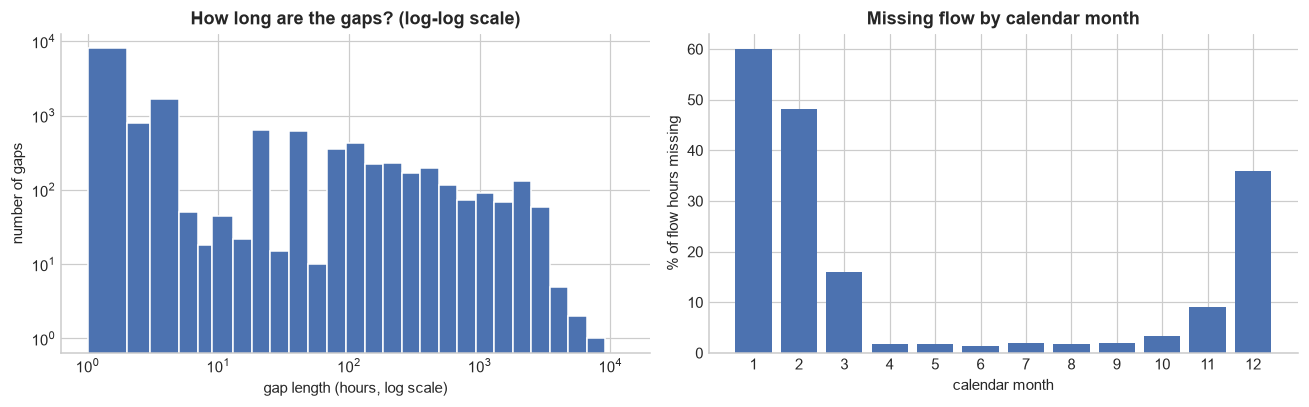

In [11]:
# how long are the gaps, and when do they happen?
gaps = np.concatenate([run_lengths(q_missing[a:b]) for a, b in offsets.values()])
long_share = gaps[gaps >= 24].sum() / gaps.sum() if gaps.sum() else np.nan
short_share = (gaps <= 3).mean() if len(gaps) else np.nan

miss_by_month = pd.Series(q_missing).groupby(df["month"].to_numpy()).mean() * 100
winter_share = q_missing[df["month"].isin([12, 1, 2, 3]).to_numpy()].sum() / max(q_missing.sum(), 1)

print(f"Number of gaps: {len(gaps):,}  | median length {np.median(gaps):.0f} h  | longest {gaps.max():,} h ({gaps.max()/24:.0f} days)")
print(f"{short_share:.0%} of gaps are 3 hours or shorter")
print(f"{long_share:.0%} of all missing hours sit inside gaps of 24 h or more -> these cannot be filled, only masked")
print(f"{winter_share:.0%} of missing hours fall in Dec-Mar (river ice)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.unique(np.logspace(0, np.log10(max(gaps.max(), 2)), 30).astype(int))
axes[0].hist(gaps, bins=bins, color=BLUE, edgecolor="white")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("gap length (hours, log scale)"); axes[0].set_ylabel("number of gaps")
axes[0].set_title("How long are the gaps? (log-log scale)")
axes[1].bar(miss_by_month.index, miss_by_month.values, color=BLUE)
axes[1].set_xticks(range(1, 13)); axes[1].set_xlabel("calendar month"); axes[1].set_ylabel("% of flow hours missing")
axes[1].set_title("Missing flow by calendar month")
savefig("05_gap_lengths_and_seasonality.png")

## 6. Suspicious values

**In plain words.** Look for readings that cannot be right or look like sensor trouble:
- **negative** flow or rain;
- **flat-lines**: exactly the same flow for 24+ hours (can be real at very low flow, so these are *flags to review*, not automatic errors);
- **one-hour spikes**: a huge jump that immediately falls back, typical of a glitch. Real floods rise and fall over many hours, so they should not be flagged.

We only **flag** here. Rows are kept so the hourly grid stays intact; the flags are saved so the modelling notebook can mask them.

In [12]:
q = df["q_cms"].to_numpy()
flag_neg = np.nan_to_num(q, nan=0.0) < 0
flag_flat = np.zeros(len(df), dtype=bool)
flag_spike = np.zeros(len(df), dtype=bool)

with np.errstate(invalid="ignore"):
    for sid, (a, b) in offsets.items():
        x = q[a:b]

        # flat-lines: identical consecutive non-missing values for >= FLAT_HOURS hours
        same = np.r_[False, (x[1:] == x[:-1]) & ~np.isnan(x[1:])]
        starts, ends = run_bounds(same)
        for s0, e0 in zip(starts, ends):
            if (e0 - s0) + 1 >= FLAT_HOURS:
                flag_flat[a + s0 - 1 : a + e0] = True

        # one-hour spikes: big jump into t that is mostly reversed by t+1
        dq = np.abs(np.diff(x))
        if np.isfinite(dq).sum() < 1000:
            continue
        thr = JUMP_MULT * np.nanpercentile(dq, 99)
        if thr <= 0:
            continue
        d1 = x[1:-1] - x[:-2]
        d2 = x[2:] - x[:-2]
        flag_spike[a + 1 : b - 1] = (np.abs(d1) > thr) & (np.abs(d2) < 0.5 * np.abs(d1))

df["flag_neg"], df["flag_flat"], df["flag_spike"] = flag_neg, flag_flat, flag_spike

flags = pd.DataFrame({"station": df["station"], "neg": flag_neg, "flat": flag_flat, "spike": flag_spike}) \
          .groupby("station", observed=True).sum()
print(f"Negative flow rows: {int(flag_neg.sum()):,}")
print(f"Flat-line hours (>= {FLAT_HOURS} h identical): {int(flag_flat.sum()):,} across {(flags['flat'] > 0).sum()} stations")
print(f"One-hour spikes: {int(flag_spike.sum()):,} across {(flags['spike'] > 0).sum()} stations")
display(flags.sort_values(["flat", "spike", "neg"], ascending=False).head(10))

Negative flow rows: 0
Flat-line hours (>= 24 h identical): 81,351 across 103 stations
One-hour spikes: 15 across 9 stations


,neg,flat,spike
station,,,
643,0,15479,0
592,0,9275,0
598,0,7238,0
617,0,4463,0
522,0,3729,1
618,0,3555,0
669,0,2989,0
671,0,2676,0
612,0,2481,0


**How to read this:** a handful of flagged hours is normal. If one station has thousands of flat-line hours, plot it (`S("<id>")["q_cms"].plot()`) and decide whether to drop that station. Do not delete rows, only mask them.

## 7. Clock check: does flow respond after rain?

**In plain words.** Rain and flow come from different agencies (NOAA and USGS) and the paper never says which time zone the timestamps use. If the clocks are off by 5–6 hours, the model would see rivers rising *before* it rains, and short-range forecasts would silently go wrong.

**The test.** For many lags *k*, compute the correlation between the hourly change in flow and the rain *k* hours earlier. If the clocks are consistent, the correlation peaks at a **positive** lag (flow rises after rain). A peak at 0 or negative lags is a warning. This uses **training years only**.

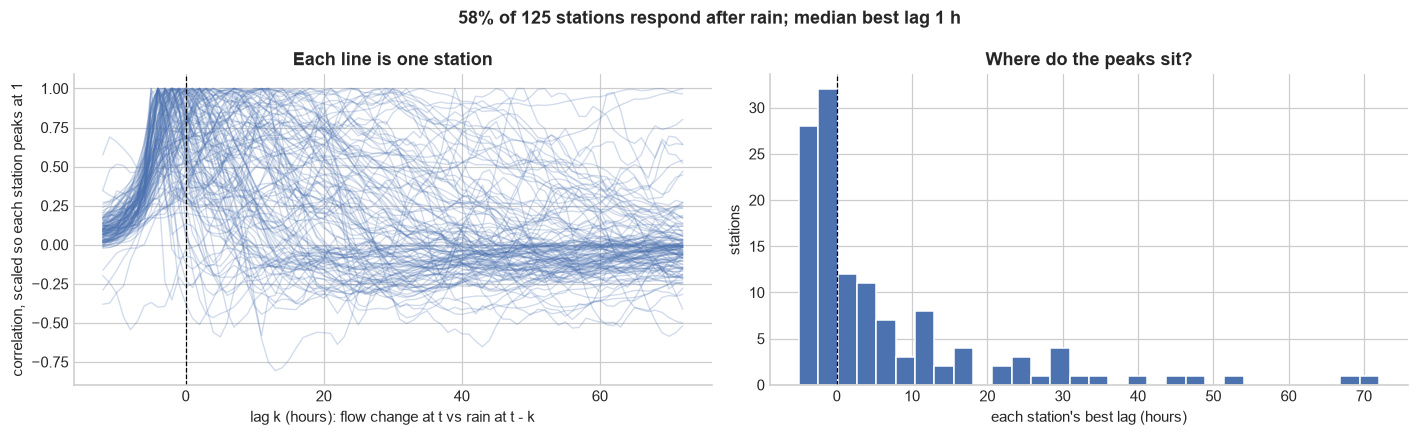

Stations with a clear rain->flow signal (peak correlation > 0.05): 125 of 125
Median best lag: +1 h | range -5 to +72 h
Best lag < 0 h (flow before rain): 42% of stations   (should be close to 0%)
Best lag = 0 h: 6%   (fine for tiny, fast catchments; many zeros would be suspicious)
-> AS SHIPPED the clocks are NOT consistent. Rain is on a different clock from flow; see the next cell, which tests and applies a fix.


In [13]:
# (a) Clock check on the rain column AS SHIPPED
LAGS = np.arange(-12, 73)
train_mask = (df["split"] == "train").to_numpy()
p_all = df["precipitation"].to_numpy(dtype=float)
q_all = df["q_cms"].to_numpy(dtype=float)

def corr_at_lag(x, y, k):
    """Correlation between flow change y(t) and rain x(t - k)."""
    if k >= 0:
        a, b = x[: len(x) - k], y[k:]
    else:
        a, b = x[-k:], y[: len(y) + k]
    m = ~(np.isnan(a) | np.isnan(b))
    if m.sum() < 500:
        return np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.corrcoef(a[m], b[m])[0, 1]

curves = {}
for sid, (a, b) in offsets.items():
    m = train_mask[a:b]
    x = p_all[a:b][m]
    qq = q_all[a:b][m]
    y = np.r_[np.nan, np.diff(qq)]            # hourly change in flow
    curves[sid] = [corr_at_lag(x, y, k) for k in LAGS]
curves = pd.DataFrame(curves, index=LAGS)

# Every station has its OWN response time (small creek = hours, big river = days), so a median of the raw
# curves would wash the peaks out. Instead we find each station's best lag and look at the distribution.
best_lag = curves.idxmax()
best_corr = curves.max()
clear = best_corr > 0.05                       # only judge stations with a visible rain->flow signal
n_clear = int(clear.sum())
if n_clear:
    neg_share = float((best_lag[clear] < 0).mean())
    zero_share = float((best_lag[clear] == 0).mean())
    med_best_lag = float(best_lag[clear].median())
else:
    neg_share = zero_share = med_best_lag = np.nan
# need a clear signal in at least half of the stations, otherwise we cannot judge the clocks at all
consistent = bool(n_clear >= 0.5 * curves.shape[1] and neg_share < 0.05 and med_best_lag >= 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
if n_clear:
    norm = curves.loc[:, clear].div(curves.loc[:, clear].max())      # each station's own peak = 1
    axes[0].plot(norm.index, norm.values, color=BLUE, alpha=0.25, lw=0.9)
    axes[1].hist(best_lag[clear], bins=min(30, max(5, n_clear)), color=BLUE, edgecolor="white")
axes[0].axvline(0, color="black", lw=0.8, ls="--")
axes[0].set_xlabel("lag k (hours): flow change at t vs rain at t - k")
axes[0].set_ylabel("correlation, scaled so each station peaks at 1")
axes[0].set_title("Each line is one station")
axes[1].axvline(0, color="black", lw=0.8, ls="--")
axes[1].set_xlabel("each station's best lag (hours)"); axes[1].set_ylabel("stations")
axes[1].set_title("Where do the peaks sit?")
if n_clear:
    fig.suptitle(f"{1 - neg_share:.0%} of {n_clear} stations respond after rain; median best lag {med_best_lag:.0f} h",
                 fontweight="bold")
else:
    fig.suptitle("No station shows a clear rain-to-flow signal: check the columns", fontweight="bold")
savefig("06_clock_check_lag_correlation.png")   # AS SHIPPED (raw rain column)

print(f"Stations with a clear rain->flow signal (peak correlation > 0.05): {n_clear} of {curves.shape[1]}")
if n_clear < 0.5 * curves.shape[1]:
    print("   Fewer than half of the stations show a clear signal inside the -12..+72 h window: widen LAGS or inspect the rain/flow columns.")
if n_clear:
    print(f"Median best lag: {med_best_lag:+.0f} h | range {best_lag[clear].min():+d} to {best_lag[clear].max():+d} h")
    print(f"Best lag < 0 h (flow before rain): {neg_share:.0%} of stations   (should be close to 0%)")
    print(f"Best lag = 0 h: {zero_share:.0%}   (fine for tiny, fast catchments; many zeros would be suspicious)")
if consistent:
    print("-> As shipped, clocks look consistent: flow follows rain.")
else:
    print("-> AS SHIPPED the clocks are NOT consistent. Rain is on a different clock from flow; see the next cell, which tests and applies a fix.")

raw_best_lag, raw_best_corr, raw_clear, raw_neg_share, raw_med = best_lag.copy(), best_corr.copy(), clear.copy(), neg_share, med_best_lag


### The fix: put rain on the same clock as flow

**In plain words.** The test above shows flow rising 4-5 hours *before* the rain that caused it, at many stations. Physically impossible, so the two columns must be on different clocks. Our working explanation (found by testing, **not stated in the paper or the authors' code**): the rain timestamps are UTC, the flow timestamps are Iowa local time (UTC-5 in summer, UTC-6 in winter). Evidence from the investigation: shifting rain by 5 h is best in summer and 6 h is best in winter, which is the daylight-saving signature.

**What we do.** Keep the original `precipitation` column untouched. Add `precip_local`: the rain that fell in each *local* hour, looked up in the UTC-labelled column using the America/Chicago time zone (so daylight saving is handled). The last 5-6 hours of the record become empty because the matching UTC rain lies beyond the end of the file. Then repeat the clock check on `precip_local`.

**Caveat.** This is an empirical correction. The 5 h / 6 h split by season is clear, but the winter sample is thin (ice gaps).

UTC offset used (hours -> number of hourly rows): {5.0: 40025, 6.0: 21343}


precip_local is empty for 0.0324% of rows (raw rain: 0.0243%); the extra empty rows are the last 5-6 h of each station


,rain as shipped,rain on local clock (precip_local)
stations with flow BEFORE rain,42%,0%
"median best lag, all stations",+1 h,+6 h
"median best lag, 17 fastest catchments (<=20 h)",-4 h,+1 h
"mean peak correlation, fastest catchments",0.347,0.349


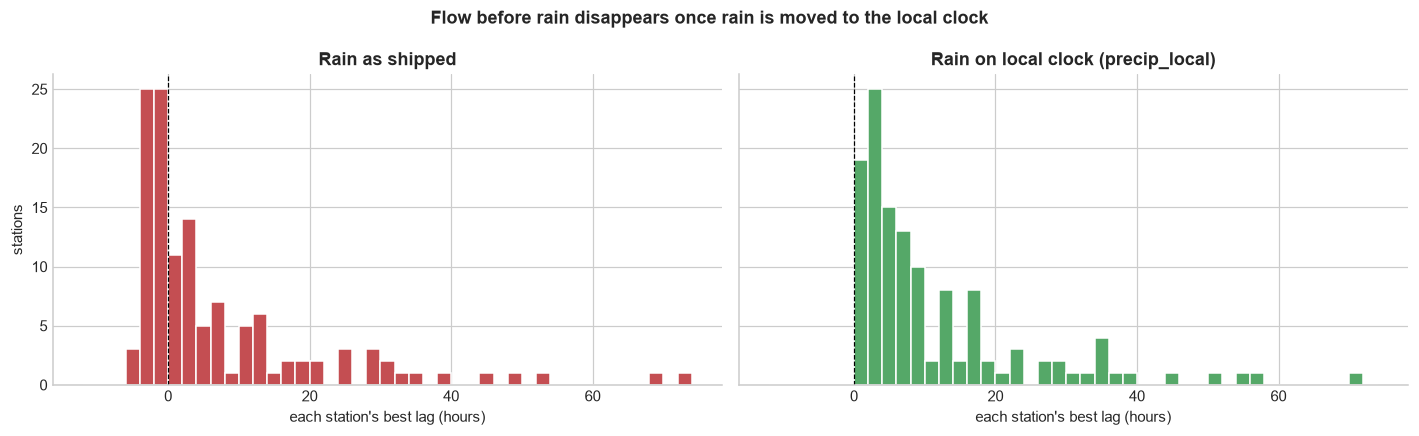

PASS - clocks consistent after correction.


In [14]:
# (b) Build precip_local = rain re-labelled to local (America/Chicago) time, then re-run the clock check
ref_dt = pd.DatetimeIndex(S(sids[0])["datetime"])
_loc = ref_dt.tz_localize("America/Chicago", ambiguous=np.ones(len(ref_dt), bool), nonexistent="shift_forward")
utc_off_h = ((_loc.tz_convert("UTC").tz_localize(None)) - ref_dt).total_seconds() / 3600     # 5 (CDT) or 6 (CST)
print("UTC offset used (hours -> number of hourly rows):", pd.Series(utc_off_h).value_counts().to_dict())

precip_local = np.full(len(df), np.nan)
for sid, (a, b) in offsets.items():
    g = df.iloc[a:b]
    p = pd.Series(g["precipitation"].to_numpy(dtype=float), index=pd.DatetimeIndex(g["datetime"]))
    off = pd.Series(utc_off_h, index=ref_dt).reindex(p.index).to_numpy()
    precip_local[a:b] = p.reindex(p.index + pd.to_timedelta(off, unit="h")).to_numpy()
df["precip_local"] = precip_local
print(f"precip_local is empty for {np.isnan(precip_local).mean():.4%} of rows (raw rain: {df['precipitation'].isna().mean():.4%}); "
      f"the extra empty rows are the last 5-6 h of each station")

# re-run the same clock check on the corrected column (training years only)
pl_all = df["precip_local"].to_numpy(dtype=float)
curves_loc = {}
for sid, (a, b) in offsets.items():
    m = train_mask[a:b]
    x = pl_all[a:b][m]
    qq = q_all[a:b][m]
    y = np.r_[np.nan, np.diff(qq)]
    curves_loc[sid] = [corr_at_lag(x, y, k) for k in LAGS]
curves_loc = pd.DataFrame(curves_loc, index=LAGS)
loc_best_lag, loc_best_corr = curves_loc.idxmax(), curves_loc.max()
loc_clear = loc_best_corr > 0.05
loc_n_clear = int(loc_clear.sum())
loc_neg_share = float((loc_best_lag[loc_clear] < 0).mean())
loc_med = float(loc_best_lag[loc_clear].median())
loc_consistent = bool(loc_n_clear >= 0.5 * curves_loc.shape[1] and loc_neg_share < 0.05 and loc_med >= 1)

fast = static.index[static["travel_time"] <= 20]
comp = pd.DataFrame({
    "rain as shipped": [f"{raw_neg_share:.0%}", f"{raw_med:+.0f} h", f"{raw_best_lag[fast].median():+.0f} h", f"{raw_best_corr[fast].mean():.3f}"],
    "rain on local clock (precip_local)": [f"{loc_neg_share:.0%}", f"{loc_med:+.0f} h", f"{loc_best_lag[fast].median():+.0f} h", f"{loc_best_corr[fast].mean():.3f}"],
}, index=["stations with flow BEFORE rain", "median best lag, all stations", f"median best lag, {len(fast)} fastest catchments (<=20 h)", "mean peak correlation, fastest catchments"])
display(comp)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
axes[0].hist(raw_best_lag[raw_clear], bins=np.arange(-12, 75, 2), color=RED, edgecolor="white")
axes[1].hist(loc_best_lag[loc_clear], bins=np.arange(-12, 75, 2), color=GREEN, edgecolor="white")
for ax, ttl in zip(axes, ["Rain as shipped", "Rain on local clock (precip_local)"]):
    ax.axvline(0, color="black", lw=0.8, ls="--"); ax.set_title(ttl); ax.set_xlabel("each station's best lag (hours)")
axes[0].set_ylabel("stations")
fig.suptitle("Flow before rain disappears once rain is moved to the local clock", fontweight="bold")
savefig("06b_clock_fix_before_after.png")

print("PASS - clocks consistent after correction." if loc_consistent else "CHECK - still not consistent after correction; investigate.")

### One real storm

**In plain words.** The classic hydrology picture: rain bars hang from the top, the river hydrograph is underneath. Seeing flow rise a few hours after the rain is the intuition behind the entire project. We pick a mid-sized, mostly complete catchment and show its biggest training-period flood.

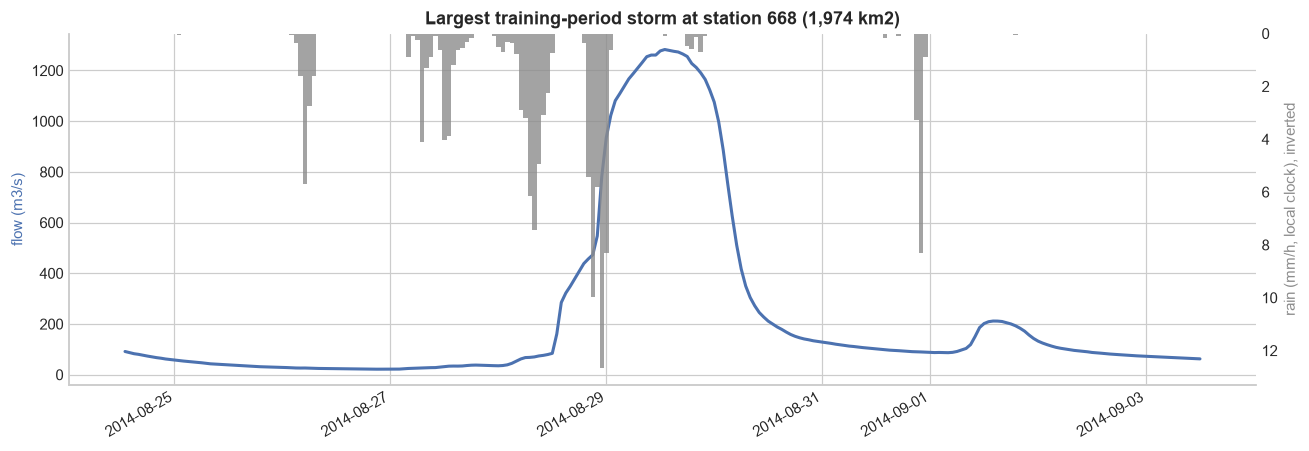

In [15]:
cand = miss_rate[miss_rate < 10].index
if len(cand) == 0:
    cand = miss_rate.index
tgt = (static.loc[cand, "area"] - static["area"].median()).abs().idxmin()

g = S(tgt)
gt = g[g["split"] == "train"]
i = int(np.nanargmax(gt["q_cms"].to_numpy()))
w = gt.iloc[max(0, i - 120): i + 120]

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(w["datetime"], w["q_cms"], color=BLUE, lw=2)
ax.set_ylabel("flow (m3/s)", color=BLUE)
ax2 = ax.twinx()
ax2.bar(w["datetime"], w["precip_local"], width=1 / 24, color=GREY, alpha=0.8)
ax2.invert_yaxis(); ax2.set_ylabel("rain (mm/h, local clock), inverted", color=GREY)
ax2.grid(False)
ax.set_title(f"Largest training-period storm at station {tgt} ({static.loc[tgt, 'area']:,.0f} km2)")
fig.autofmt_xdate()
savefig("07_example_storm.png")

## 8. Save the cleaned data and write down what we learned

**In plain words.** We save the cleaned table (with flags and split labels) so the next notebook starts here instead of re-loading 125 files. Then we print the key numbers as sentences. These are your first findings.

In [16]:
keep = ["datetime", "station", "split", "wy", "precipitation", "precip_local", "et", "discharge", "q_cms",
        "flag_neg", "flag_flat", "flag_spike"]
try:
    df[keep].to_parquet(OUT_DIR / "waterbench_ts_clean.parquet", index=False)
    print("saved", OUT_DIR / "waterbench_ts_clean.parquet")
except Exception as e:
    print("parquet failed (", type(e).__name__, ") -> saving compressed CSV instead")
    df[keep].to_csv(OUT_DIR / "waterbench_ts_clean.csv.gz", index=False)

station_summary = static.join(miss_rate.rename("flow_missing_pct")).join(flags)
station_summary.to_csv(OUT_DIR / "static_attributes.csv")
print("saved", OUT_DIR / "static_attributes.csv")

saved processed/waterbench_ts_clean.parquet
saved processed/static_attributes.csv


In [17]:
print("FINDINGS SO FAR (copy these into your slides, with the figure numbers)\n")
print(f"1. Data: {len(offsets)} gauges x {EXPECTED_ROWS:,} hourly rows = {len(df):,} rows, 1 Oct 2011 to 30 Sep 2018.")
print(f"2. Catchments range from {static['area'].min():,.0f} to {static['area'].max():,.0f} km2 (median {static['area'].median():,.0f}); "
      f"concentration time {static['travel_time'].min():.0f} to {static['travel_time'].max():.0f} h (median {static['travel_time'].median():.0f}). Fig 01.")
print(f"3. Flow is missing for a median of {miss_rate.median():.1f}% of hours per gauge (range {miss_rate.min():.1f}-{miss_rate.max():.1f}%); rain is almost complete. Fig 03, 04.")
print(f"4. {long_share:.0%} of missing hours are in gaps of 24 h or more, and {winter_share:.0%} fall in Dec-Mar. "
      f"-> mask missing flow in the loss; do not interpolate targets. Fig 05.")
print(f"5. {int(flag_flat.sum()):,} flat-line hours, {int(flag_spike.sum()):,} one-hour spikes and {int(flag_neg.sum()):,} negative values flagged for review.")
print(f"6. Clock problem found and fixed: as shipped, {raw_neg_share:.0%} of {int(raw_clear.sum())} stations show flow rising BEFORE rain (fastest catchments peak 4-5 h early). "
      f"Rain looks like UTC, flow like Iowa local time (5 h in summer, 6 h in winter). After converting rain to local time (precip_local) the share is {loc_neg_share:.0%}; "
      f"clock check: {'PASS' if loc_consistent else 'CHECK'}. Empirical, not documented by the authors. Fig 06, 06b.")
print(f"7. River network: {rel['station_id'].nunique()} gauges have an upstream gauge, giving extra warning time for the gate. Fig 02.")

FINDINGS SO FAR (copy these into your slides, with the figure numbers)

1. Data: 125 gauges x 61,368 hourly rows = 7,671,000 rows, 1 Oct 2011 to 30 Sep 2018.
2. Catchments range from 6 to 36,453 km2 (median 1,918); concentration time 2 to 315 h (median 53). Fig 01.
3. Flow is missing for a median of 16.1% of hours per gauge (range 0.7-33.1%); rain is almost complete. Fig 03, 04.
4. 99% of missing hours are in gaps of 24 h or more, and 87% fall in Dec-Mar. -> mask missing flow in the loss; do not interpolate targets. Fig 05.
5. 81,351 flat-line hours, 15 one-hour spikes and 0 negative values flagged for review.
6. Clock problem found and fixed: as shipped, 42% of 125 stations show flow rising BEFORE rain (fastest catchments peak 4-5 h early). Rain looks like UTC, flow like Iowa local time (5 h in summer, 6 h in winter). After converting rain to local time (precip_local) the share is 0%; clock check: PASS. Empirical, not documented by the authors. Fig 06, 06b.
7. River network: 63 gauges

### Finding -> decision table

| Finding | Decision for modelling |
|---|---|
| Flow is missing for a median of ~16% of hours per gauge (0.7-33%), 99% of it in gaps of 24 h or more, mostly Dec-Mar (ice) | Mask missing flow in the loss. Never interpolate targets. Short gaps (<= 3 h) in *inputs* may be filled, with an "imputed" flag. |
| Catchments span 6 to 36,453 km2, concentration time 2 to 315 h | One regional model with static attributes as inputs; report skill per size group, per station. |
| Rain timestamps are about 5-6 h ahead of flow timestamps (rain looks like UTC, flow like local time); verified on 125 stations, DST pattern visible | Use `precip_local` for every rain feature and for any future-rain scenario. Never use raw `precipitation`. Record as empirical, not documented. |
| Without the fix, rain labelled 4-5 h in the future already explains current flow | The perfect / degraded / no-future-rain experiment is only valid on `precip_local`. |
| 81k flat-line hours, 15 one-hour spikes, 0 negatives | Flag and mask; check whether a few stations hold most flat-lines before deciding to drop any. |
| 63 gauges have upstream gauges | Add upstream flow as a feature, lagged by the measured travel time (notebook 02). |